# 2. Data Understanding: Eksplorasi dan Pemahaman Citra Satelit Sentinel-2 L2A

Tahap **Data Understanding** dalam metodologi **CRISP-DM** bertujuan untuk memahami karakteristik data citra satelit yang diperoleh, memverifikasi kualitas sampel lapangan (*ground truth*), memeriksa integritas statistik sebaran data, serta mengidentifikasi pola fisik pantulan spektral dari masing-masing kelas tutupan lahan di wilayah Provinsi Jawa Timur.

Fokus eksplorasi data diarahkan pada pembuktian **Strategi Separasi Dua Arah Mutual (*Mutual Disambiguation*)** menggunakan **5 Indeks Biofisik Terarah (REMI, NDVI, IBI, MNDWI, NDWI)** yang diturunkan dari 7 pita spektral dasar Sentinel-2 Level-2A.

---

### Kebutuhan Data dan Parameter Teknis:
1. **Sensor dan Misi Satelit**: Satelit Copernicus Sentinel-2 Multi-Spectral Instrument (MSI), dikelola oleh European Space Agency (ESA).
2. **Tingkat Pemrosesan Citra (*Processing Level*)**: Sentinel-2 Level-2A (L2A), menyediakan data pantulan permukaan tanah (*Bottom-of-Atmosphere / BOA Surface Reflectance*) terkoreksi atmosfer.
3. **Pita Spektral (*Bands*) yang Digunakan**: 7 saluran spektral utama:
   * **B02 (Blue, 490 nm)**: Cahaya tampak biru (resolusi spasial 10m).
   * **B03 (Green, 560 nm)**: Cahaya tampak hijau (resolusi spasial 10m).
   * **B04 (Red, 665 nm)**: Cahaya tampak merah (resolusi spasial 10m).
   * **B08 (Broad NIR, 842 nm)**: Inframerah dekat lebar (resolusi spasial 10m).
   * **B8A (Narrow NIR, 865 nm)**: Inframerah dekat sempit / red edge (resolusi spasial 20m).
   * **B11 (SWIR-1, 1610 nm)**: Inframerah gelombang pendek 1 (resolusi spasial 20m).
   * **B12 (SWIR-2, 2190 nm)**: Inframerah gelombang pendek 2 (resolusi spasial 20m).
4. **Metode Pengambilan Sampel (*Ground Truth Sampling*)**: 250 poligon representatif (50 sampel per kelas seimbang sempurna) di berbagai kabupaten/kota di Jawa Timur dalam format GeoJSON.
5. **Mekanisme Ekstraksi Reflektansi**: Menggunakan skrip Python terintegrasi (`extract_sentinel2_samples.py`) yang terhubung ke **Copernicus Data Space Ecosystem (CDSE) Process API** untuk mengunduh nilai piksel dan poligon bebas awan (*cloud coverage < 5%*).


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
from rasterio.plot import show
from dotenv import load_dotenv

# atur gaya visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('[OK] Seluruh library berhasil dimuat.')


[OK] Seluruh library berhasil dimuat.


## 2.1 Pemuatan Data Sampel Poligon dan Dataset Piksel

Pada tahap ini dimuat dua tingkatan dataset hasil ekstraksi satelit Sentinel-2:
1. **Dataset Piksel (`sentinel2_pixels_dataset.csv`)**: Terdiri dari **12.500 baris sampel piksel individu** (50 piksel per poligon). Dataset piksel ini merupakan **basis utama pemodelan klasifikasi (*main training & testing input*)** untuk menghasilkan peta tutupan lahan resolusi tinggi per piksel 10m x 10m yang tajam dan akurat.
2. **Dataset Poligon (`sentinel2_sample_polygons.csv`)**: Terdiri dari **250 baris poligon** (50 sampel per kelas seimbang), mewakili batas *ground truth* lapangan asli. Dataset ini berfungsi sebagai kontrol kualitas batas spasial, kunci partisi data latih-uji bebas bocor (*spatial group split*), dan evaluasi konsensus area tematik.

> Catatan Metodologi:
> Seluruh 12.500 piksel terdistribusi seimbang sempurna (2.500 piksel per kelas) dan bersumber dari 250 poligon lapangan terverifikasi di Jawa Timur, menjamin model terbebas dari bias kelas mayoritas.


In [2]:
# muat dataset poligon dan dataset piksel hasil ekstraksi
data_dir = 'extracted_data'
df_poly = pd.read_csv(os.path.join(data_dir, 'sentinel2_sample_polygons.csv'))
df_pixels = pd.read_csv(os.path.join(data_dir, 'sentinel2_pixels_dataset.csv'))

# tampilkan jumlah baris dan sebaran sampel
print(f'Jumlah Sampel Poligon: {len(df_poly)} baris')
print(f'Jumlah Sampel Piksel : {len(df_pixels)} baris')
print('\nDistribusi Sampel Poligon per Kelas:')
display(df_poly['class_name'].value_counts())


Jumlah Sampel Poligon: 250 baris
Jumlah Sampel Piksel : 12500 baris

Distribusi Sampel Poligon per Kelas:


class_name
bangunan     50
hutan        50
mangrove     50
perairan     50
pertanian    50
Name: count, dtype: int64

## 2.2 Analisis Statistik Spektral dan Indeks Berdasarkan Kelas

Tabel di bawah menyajikan nilai rata-rata pantulan spektral (*mean reflectance*) 7 band Sentinel-2 beserta **5 Indeks Biofisik Terarah** untuk setiap kategori tutupan lahan di Jawa Timur.

### Karakteristik Fisis 5 Indeks Biofisik Terarah:
1. **`REMI` (*Red Edge Mangrove Index*)**: Menangkap kontras antara pantulan kanopi *Red-Edge* ($B8A$) dan serapan lumpur/air payau pada SWIR-1 ($B11$); menonjolkan Mangrove dan meredam Hutan Darat.
2. **`NDVI` (*Normalized Difference Vegetation Index*)**: Mengukur kerapatan klorofil kanopi aktif dari pita $B08$ dan $B04$; bermitra dengan REMI memisahkan Hutan Darat vs Mangrove.
3. **`IBI` (*Index-based Built-up Index*)**: Menyorot material bangunan perkotaan melalui NDBI dengan peredaman simultan SAVI dan MNDWI; secara aktif meredam tanah kosong dan sawah kering.
4. **`MNDWI` (*Modified Normalized Difference Water Index*)**: Mendeteksi kelengasan substrat dan air dangkal pada sawah berair/kosongan; membedakannya dari perairan murni.
5. **`NDWI` (*Normalized Difference Water Index*)**: Menarik garis batas air terbuka murni (sungai, danau, laut) yang tegas berkat serapan total pita NIR ($B08$).


In [3]:
# hitung rata-rata spektral 7 band dan 5 indeks terarah per kelas
bands_and_indices = ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12', 'REMI', 'NDVI', 'IBI', 'MNDWI', 'NDWI']
summary_table = df_poly.groupby('class_name')[bands_and_indices].mean().reset_index()

# tampilkan ringkasan statistik per kelas
display(summary_table.round(4))


,class_name,B02,B03,B04,B08,B8A,B11,B12,REMI,NDVI,IBI,MNDWI,NDWI
0,bangunan,0.1678,0.1844,0.2071,0.2491,0.2596,0.3084,0.2912,0.4964,0.1157,2.2885,-0.2907,-0.1893
1,hutan,0.1649,0.1759,0.1672,0.3358,0.3527,0.2646,0.1867,3.8332,0.5019,1.7502,-0.3593,-0.4646
2,mangrove,0.1003,0.1172,0.0910,0.3144,0.3218,0.1576,0.0873,3.5612,0.6650,1.6423,-0.2712,-0.5592
3,perairan,0.1058,0.1135,0.0975,0.0863,0.0913,0.0784,0.0635,1.2718,-0.0535,-0.9393,0.1881,0.1394
4,pertanian,0.0770,0.1036,0.1132,0.2436,0.2598,0.2339,0.1658,0.7872,0.3802,5.7851,-0.3692,-0.4016


## 2.3 Profil Tanda Tangan Spektral (*Spectral Signatures*)

Setiap objek tutupan lahan memiliki kurva tanda tangan spektral (*spectral signature*) yang mencerminkan interaksi material terhadap spektrum elektromagnetik:

* **Perairan (*Water Body*)**: Kurva menurun tajam; menyerap hampir seluruh gelombang inframerah (NIR dan SWIR).
* **Bangunan (*Built-up*)**: Pantulan meningkat bertahap hingga memuncak pada SWIR-1 ($B11$) akibat material semen/atap beton kering.
* **Vegetasi (Hutan, Mangrove, Pertanian)**: Mengalami fenomena *Red Edge*, yaitu serapan kuat klorofil pada pita Red ($B04$) dan lonjakan pantulan tinggi pada pita NIR ($B08$ & $B8A$).


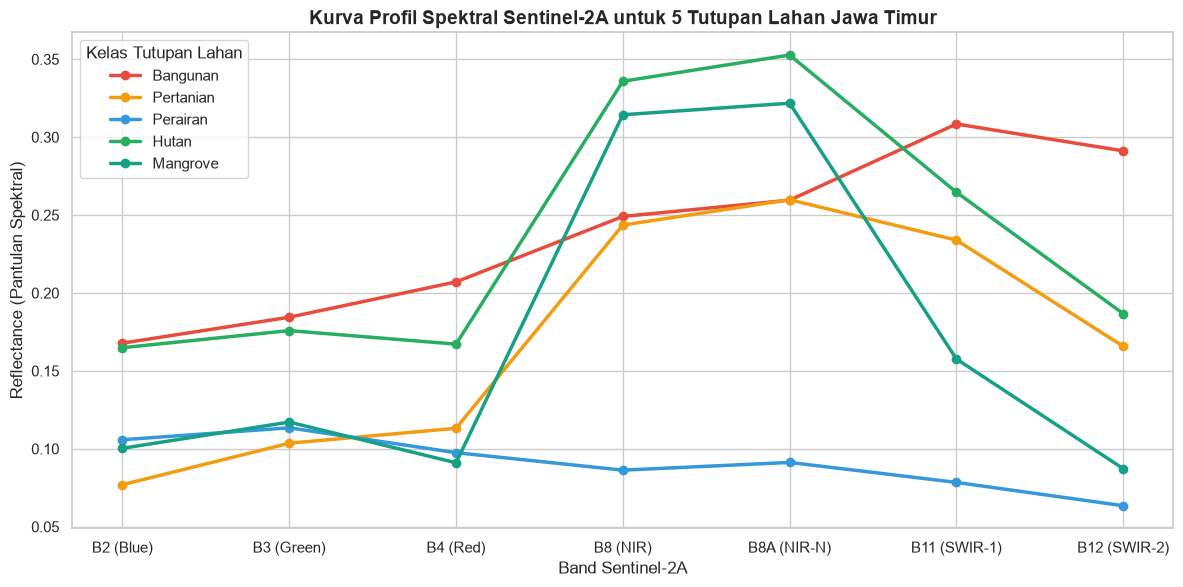

In [4]:
# definisikan pita spektral sentinel-2 dan warna kelas
band_cols = ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12']
band_names = ['B2 (Blue)', 'B3 (Green)', 'B4 (Red)', 'B8 (NIR)', 'B8A (NIR-N)', 'B11 (SWIR-1)', 'B12 (SWIR-2)']
palette = {'bangunan': '#e74c3c', 'pertanian': '#f39c12', 'perairan': '#3498db', 'hutan': '#27ae60', 'mangrove': '#16a085'}

# visualisasikan kurva tanda tangan spektral rata-rata
fig, ax = plt.subplots(figsize=(12, 6))
for cls in ['bangunan', 'pertanian', 'perairan', 'hutan', 'mangrove']:
    cls_data = df_poly[df_poly['class_name'] == cls][band_cols].mean()
    ax.plot(band_names, cls_data.values, marker='o', linewidth=2.5, label=cls.capitalize(), color=palette[cls])

ax.set_title('Kurva Profil Spektral Sentinel-2A untuk 5 Tutupan Lahan Jawa Timur', fontsize=14, fontweight='bold')
ax.set_xlabel('Band Sentinel-2A', fontsize=12)
ax.set_ylabel('Reflectance (Pantulan Spektral)', fontsize=12)
ax.legend(title='Kelas Tutupan Lahan', fontsize=11)
plt.tight_layout()
plt.show()


## 2.4 Analisis Karakteristik Separasi Dua Arah: Evaluasi 5 Indeks Biofisik Terarah

Tantangan terbesar klasifikasi tutupan lahan di Jawa Timur adalah menghindari ambiguitas spektral silang (*bi-directional confusion*). Tiga pasangan pemisahan kritis dibuktikan secara empiris melalui 5 indeks biofisik terarah:

1. **Pemisahan Mangrove vs Hutan Darat (REMI vs NDVI)**: 
   * Kanopi keduanya sama-sama lebat (NDVI tinggi), namun substrat lumpur basah intertidal mangrove menyerap SWIR-1 ($B11$) secara drastis, sehingga nilai **REMI pada mangrove terdongkrak jauh lebih tinggi** dibanding hutan daratan.
2. **Pemisahan Bangunan vs Tanah Kosong / Sawah Kering (IBI)**:
   * NDBI konvensional sering tertukar antara bangunan dan tanah kering. Formula **IBI meredam respon tanah latar belakang** melalui pengurangan gabungan SAVI dan MNDWI, mengunci nilai positif hanya pada material buatan manusia.
3. **Pemisahan Sawah Berair vs Perairan Terbuka Murni (MNDWI vs NDWI)**:
   * Sawah berair memiliki nilai MNDWI moderat karena kelengasan tanah lumpur, namun **NDWI perairan murni jauh lebih tinggi dan tegas** karena air dalam menyerap NIR secara total.


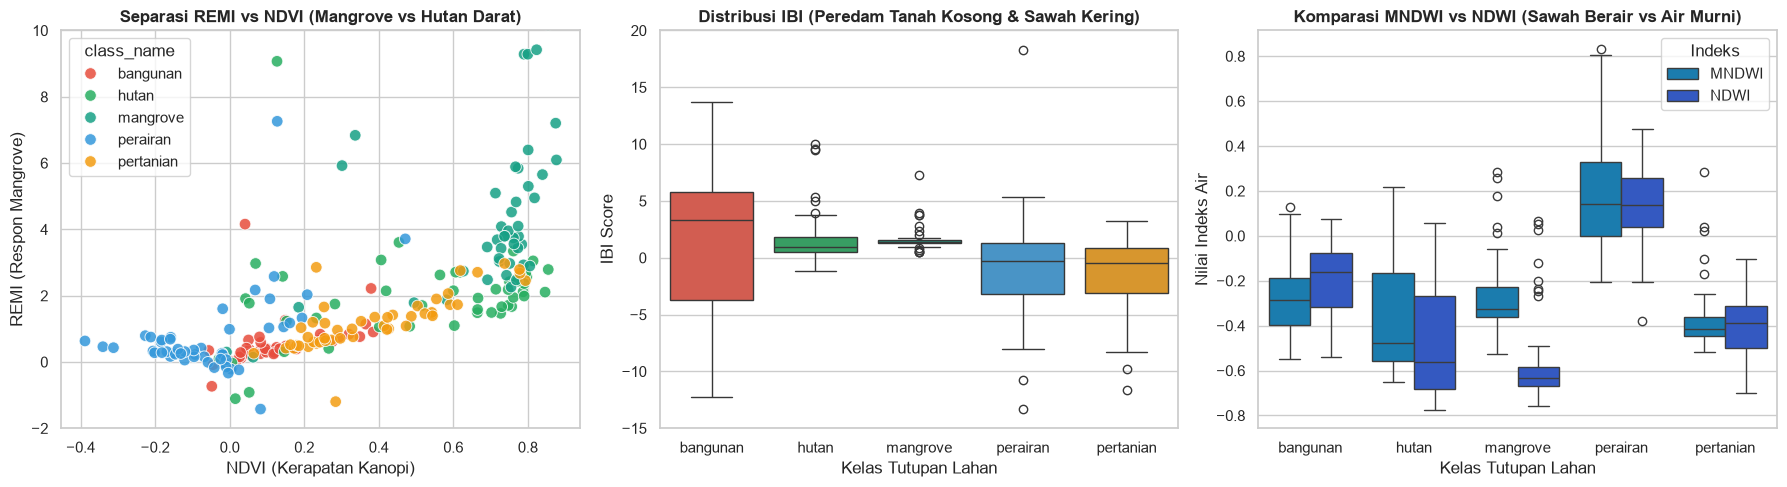

In [5]:
# visualisasi pemisahan dua arah 5 indeks terarah
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# scatter plot pemisahan mangrove vs hutan darat (remi vs ndvi)
sns.scatterplot(data=df_poly, x='NDVI', y='REMI', hue='class_name', palette=palette, s=70, alpha=0.85, ax=axes[0])
axes[0].set_title('Separasi REMI vs NDVI (Mangrove vs Hutan Darat)', fontweight='bold')
axes[0].set_xlabel('NDVI (Kerapatan Kanopi)')
axes[0].set_ylabel('REMI (Respon Mangrove)')
axes[0].set_ylim(-2, 10)

# boxplot isolasi bangunan dan peredaman tanah kosong (ibi)
sns.boxplot(data=df_poly, x='class_name', y='IBI', hue='class_name', palette=palette, legend=False, ax=axes[1])
axes[1].set_title('Distribusi IBI (Peredam Tanah Kosong & Sawah Kering)', fontweight='bold')
axes[1].set_xlabel('Kelas Tutupan Lahan')
axes[1].set_ylabel('IBI Score')
axes[1].set_ylim(-15, 20)

# boxplot pemisahan sawah berair vs perairan murni (mndwi vs ndwi)
df_melt = pd.melt(df_poly, id_vars=['class_name'], value_vars=['MNDWI', 'NDWI'], var_name='Indeks', value_name='Nilai')
sns.boxplot(data=df_melt, x='class_name', y='Nilai', hue='Indeks', palette={'MNDWI': '#0284c7', 'NDWI': '#1d4ed8'}, ax=axes[2])
axes[2].set_title('Komparasi MNDWI vs NDWI (Sawah Berair vs Air Murni)', fontweight='bold')
axes[2].set_xlabel('Kelas Tutupan Lahan')
axes[2].set_ylabel('Nilai Indeks Air')

plt.tight_layout()
plt.show()


## 2.5 Eksplorasi Visual Spasial Citra Satelit Regional Sentinel-2 (GeoTIFF)

Visualisasi citra satelit GeoTIFF disajikan dalam dua komposit spektral:
1. **Komposit True Color (B4-Red, B3-Green, B2-Blue)**: Menampilkan kenampakan alami bentang alam Jawa Timur sesuai penglihatan mata manusia.
2. **Komposit False Color CIR (B8-NIR, B4-Red, B3-Green)**: Menyorot vegetasi dalam warna merah menyala, memudahkan identifikasi batas sebaran hutan dan lahan pertanian dari perairan.


Ukuran Citra Raster: 1024 x 1024 piksel, 7 band
Sistem Koordinat (CRS): EPSG:4326
Bounding Box: BoundingBox(left=112.5, bottom=-7.6, right=113.0, top=-7.0)


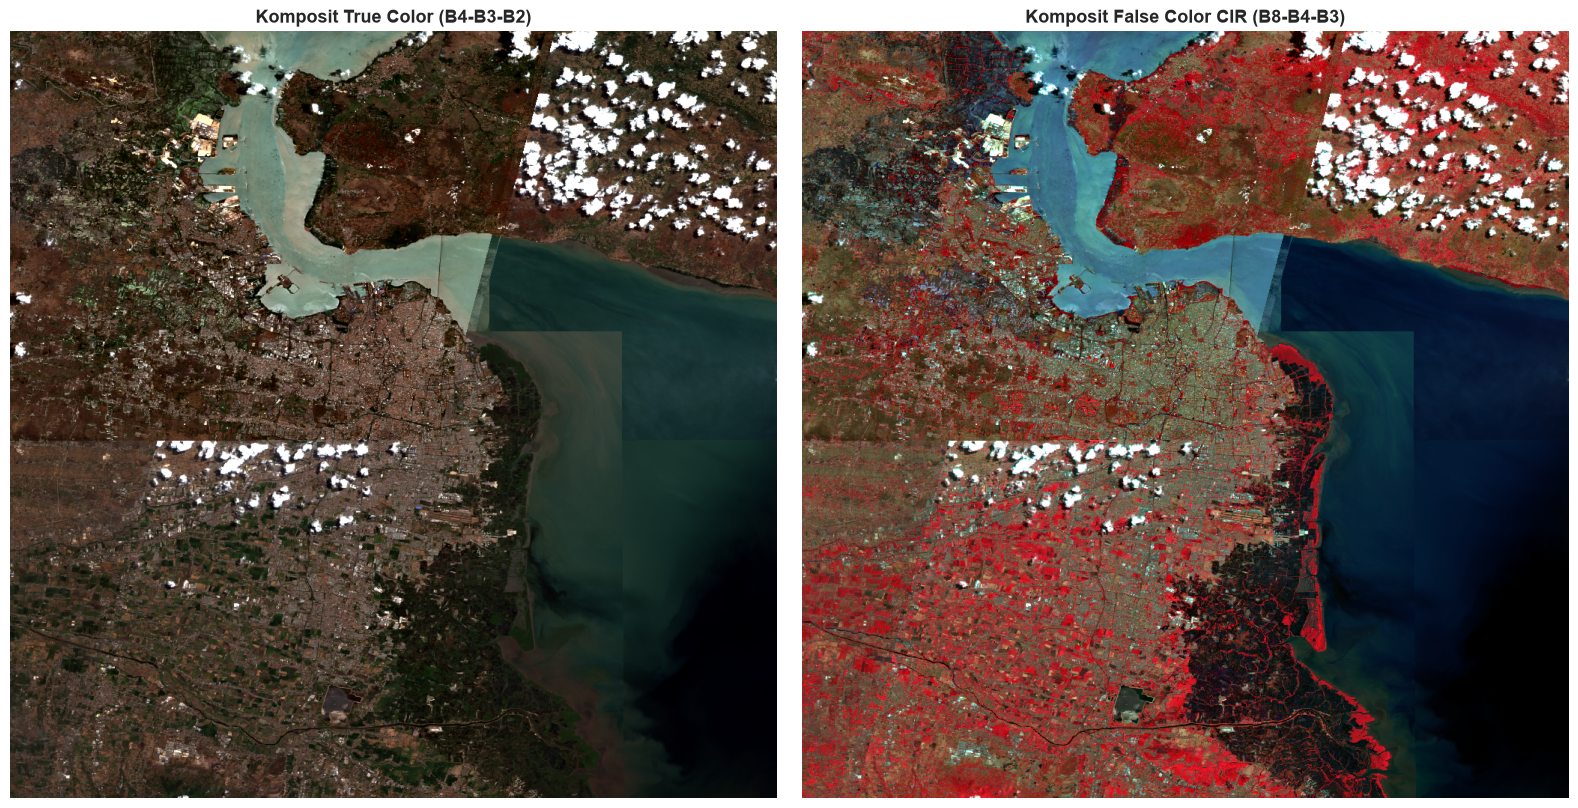

In [6]:
# muat raster citra satelit regional jatim
tif_path = os.path.join(data_dir, 'sentinel2_jatim_scene.tif')
if os.path.exists(tif_path):
    with rasterio.open(tif_path) as src:
        print(f'Ukuran Citra Raster: {src.width} x {src.height} piksel, {src.count} band')
        print(f'Sistem Koordinat (CRS): {src.crs}')
        print(f'Bounding Box: {src.bounds}')
        
        b2 = src.read(1)
        b3 = src.read(2)
        b4 = src.read(3)
        b8 = src.read(4)
        
        # normalisasi pita spektral untuk komposit citra
        def normalize_band(b):
            b_min, b_max = np.nanpercentile(b, (2, 98))
            return np.clip((b - b_min) / (b_max - b_min + 1e-8), 0, 1)
        
        # tampilkan komposit true color dan false color nir
        rgb_true = np.dstack([normalize_band(b4), normalize_band(b3), normalize_band(b2)])
        rgb_false = np.dstack([normalize_band(b8), normalize_band(b4), normalize_band(b3)])
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
        ax1.imshow(rgb_true)
        ax1.set_title('Komposit True Color (B4-B3-B2)', fontsize=13, fontweight='bold')
        ax1.axis('off')
        
        ax2.imshow(rgb_false)
        ax2.set_title('Komposit False Color CIR (B8-B4-B3)', fontsize=13, fontweight='bold')
        ax2.axis('off')
        
        plt.tight_layout()
        plt.show()


## 2.6 Visualisasi Geospasial: Peta 2D Interaktif Persebaran 250 Sampel Lapangan

Peta interaktif Leaflet menyajikan visualisasi spasial 250 poligon sampel representatif (50 sampel per kelas seimbang) di Jawa Timur.

### Fitur Interaktif Peta:
1. **Pilihan Basemap Satelit**: Esri World Imagery, Google Satellite Hybrid, dan OpenStreetMap.
2. **Sebaran 5 Kelas Sampel Tematik**: Bangunan (merah), Pertanian (amber), Perairan (biru), Hutan Daratan (hijau emerald), dan Hutan Mangrove (hijau toska).
3. **Popup Informasi Spektral Lengkap**: Menampilkan nilai pantulan 7 band reflektansi dasar dan **5 Indeks Biofisik Terarah (REMI, NDVI, IBI, MNDWI, NDWI)**.
4. **Kontrol Layer Selektif**: Mengaktifkan atau menonaktifkan layer kelas tertentu untuk verifikasi lapangan.


In [7]:
import os
import json
import folium
import branca
from folium import plugins
import pandas as pd

# muat data sampel dan inisialisasi peta terpusat jawa timur
data_dir = 'extracted_data'
geojson_dir = 'sampling_geojson'
df_poly = pd.read_csv(os.path.join(data_dir, 'sentinel2_sample_polygons.csv'))
lookup_df = df_poly.set_index('sample_id')

map_center = [-7.65, 112.5]
m = folium.Map(location=map_center, zoom_start=8, control_scale=True, tiles=None)

# tambahkan pilihan layer basemap satelit
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery',
    name='Esri World Imagery (Satelit Default)',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Hybrid',
    name='Google Satellite Hybrid',
    overlay=False,
    control=True
).add_to(m)

folium.TileLayer(
    'OpenStreetMap',
    name='OpenStreetMap (Peta Jalan)',
    overlay=False,
    control=True
).add_to(m)

# konfigurasi kelas dan warna sampel
class_configs = {
    'bangunan': {'name': 'Bangunan (Built-up)', 'color': '#EF4444', 'file': 'bangunan.geojson'},
    'pertanian': {'name': 'Lahan Pertanian (Farmland)', 'color': '#D97706', 'file': 'pertanian.geojson'},
    'perairan': {'name': 'Perairan (Water Body)', 'color': '#0284C7', 'file': 'perairan.geojson'},
    'hutan': {'name': 'Hutan Daratan (Forest)', 'color': '#16A34A', 'file': 'hutan.geojson'},
    'mangrove': {'name': 'Hutan Mangrove (Mangrove)', 'color': '#0D9488', 'file': 'mangrove.json'}
}

# buat layer poligon dan popup informasi 7 band serta 5 indeks terarah
for class_key, conf in class_configs.items():
    fg_class = folium.FeatureGroup(name=f"{conf['name']} (50 Sampel)", show=True)
    file_path = os.path.join(geojson_dir, conf['file'])
    if os.path.exists(file_path):
        with open(file_path, 'r', encoding='utf-8') as fp:
            geo_data = json.load(fp)
        for i, feat in enumerate(geo_data.get('features', [])):
            sample_id = f'{class_key}_{i+1:03d}'
            row = lookup_df.loc[sample_id] if sample_id in lookup_df.index else None
            if row is not None:
                popup_html = (
                    f'<div style="font-family: -apple-system, BlinkMacSystemFont, Segoe UI, Roboto, sans-serif; min-width: 250px; font-size: 12px; border-radius: 8px; overflow: hidden; box-shadow: 0 2px 8px rgba(0,0,0,0.15);">'
                    f'<div style="background: {conf["color"]}; color: white; padding: 6px 10px; font-weight: 700; font-size: 13px;">{conf["name"]}</div>'
                    f'<div style="padding: 8px 10px; background: #FFFFFF; color: #1E293B; line-height: 1.5;">'
                    f'<div><b>ID Sampel:</b> <code style="background:#F1F5F9; padding:1px 4px; border-radius:3px;">{sample_id}</code></div>'
                    f'<div><b>Koordinat:</b> {row["centroid_lat"]:.4f}° LS, {row["centroid_lon"]:.4f}° BT</div>'
                    f'<div><b>Luas Sampel:</b> {int(row["pixel_count"]):,} piksel</div>'
                    f'<hr style="margin: 6px 0; border: none; border-top: 1px solid #E2E8F0;">'
                    f'<div style="font-weight: 600; color: #475569; margin-bottom: 2px;">Reflektansi Band Sentinel-2:</div>'
                    f'<div style="font-family: monospace; font-size: 11px; color: #334155;">'
                    f'B02: {row["B02"]:.3f} | B03: {row["B03"]:.3f} | B04: {row["B04"]:.3f}<br>'
                    f'B08: {row["B08"]:.3f} | B8A: {row["B8A"]:.3f}<br>'
                    f'B11: {row["B11"]:.3f} | B12: {row["B12"]:.3f}'
                    f'</div>'
                    f'<hr style="margin: 6px 0; border: none; border-top: 1px solid #E2E8F0;">'
                    f'<div style="font-weight: 600; color: #475569; margin-bottom: 2px;">5 Indeks Biofisik Terarah:</div>'
                    f'<div style="font-size: 11px;">'
                    f'REMI: <b style="color:#0D9488;">{row["REMI"]:.3f}</b> | NDVI: <b style="color:#16A34A;">{row["NDVI"]:.3f}</b><br>'
                    f'IBI: <b style="color:#EF4444;">{row["IBI"]:.3f}</b> | MNDWI: <b style="color:#0284C7;">{row["MNDWI"]:.3f}</b><br>'
                    f'NDWI: <b style="color:#1D4ED8;">{row["NDWI"]:.3f}</b>'
                    f'</div>'
                    f'</div></div>'
                )

                # tandai titik centroid poligon
                folium.CircleMarker(
                    location=[row['centroid_lat'], row['centroid_lon']],
                    radius=5.5,
                    color='#FFFFFF',
                    weight=1.5,
                    fill=True,
                    fill_color=conf['color'],
                    fill_opacity=0.9,
                    tooltip=f"{conf['name']}: {sample_id}",
                    popup=folium.Popup(popup_html, max_width=300)
                ).add_to(fg_class)
            else:
                popup_html = f"<b>{conf['name']}</b><br>ID: {sample_id}"
        
        # tambahkan batas poligon geojson
        folium.GeoJson(
            geo_data,
            style_function=lambda x, c=conf['color']: {'fillColor': c, 'color': c, 'weight': 2, 'fillOpacity': 0.35}
        ).add_to(fg_class)
        fg_class.add_to(m)

# tambahkan kontrol layer dan pengukuran peta
folium.LayerControl(collapsed=False).add_to(m)
plugins.MeasureControl(position='topleft', primary_length_unit='kilometers').add_to(m)
plugins.Fullscreen(position='topleft').add_to(m)

# render peta interaktif
m
